# Projet tutoré — Classification automatique de documents médicaux hétérogènes

### Encadrant
Zakariyaa ISMAILI

### Binôme
- Kadidiatou Dem
- Hiba Chach

In [3]:
import os
from pathlib import Path
from glob import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import pytesseract
from PIL import Image
import os
import hashlib
import cv2
import re
import time
import joblib
import easyocr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)
import pytesseract
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset
import torch.nn as nn
from torchvision import transforms
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (resnet50,
    efficientnet_b0)

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import albumentations as A

from albumentations.pytorch import ToTensorV2

from torch.utils.tensorboard import SummaryWriter

import pytorch_lightning as pl
from torchvision import models
from torchvision.models import resnet50
from pytorch_lightning.callbacks import ModelCheckpoint

2026-05-29 12:16:57.980606: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780057018.430117      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780057018.560592      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780057019.614681      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780057019.614727      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780057019.614730      58 computation_placer.cc:177] computation placer alr

##### Deep Learning sur images

###### dataset (rvlcdip)

In [5]:
RVL_PATH = Path("/kaggle/input/datasets/orllem456/rvlcdip")
MED_PATH = Path("/kaggle/input/datasets/andrewmvd/medical-mnist")

print("RVL exists:", RVL_PATH.exists())
print("MED exists:", MED_PATH.exists())

RVL exists: True
MED exists: True


In [6]:
splits = ["train", "val", "test"]
data = []
for split in splits:
    label_file = RVL_PATH / "labels" / f"{split}.txt"
    
    with open(label_file, "r") as f:
        for line in f:
            path, label = line.strip().split()
            data.append((path, int(label), split))
df_rvl = pd.DataFrame(data, columns=["path", "label", "split"])
df_rvl.head()

,path,label,split
0,imagesq/q/o/c/qoc54c00/80035521.tif,15,train
1,imagese/e/w/c/ewc23d00/513280028.tif,1,train
2,imagesw/w/b/t/wbt26e00/2053453161.tif,7,train
3,imagesm/m/k/m/mkm05e00/2040792992_2040792994.tif,10,train
4,imageso/o/e/x/oex80d00/522787731+-7732.tif,3,train


In [7]:
rvl_classes = [
"letter","form","email","handwritten","advertisement",
"scientific report","scientific publication","specification",
"file folder","news article","budget","invoice",
"presentation","questionnaire","resume","memo"
]

df_rvl["class_name"] = df_rvl["label"].map(lambda x: rvl_classes[x])

In [8]:
#transformez RVL-CDIP en dataset “pseudo médical”
project_mapping = {
    "letter": "lettre_liaison",

    "form": "certificat_medical",

    "email": "administratif",

    "handwritten": "consultation",

    "scientific report": "biologie",

    "scientific publication": "imagerie",

    "invoice": "administratif",

    "memo": "ordonnance",

    "specification": "autre",

    "questionnaire": "autre"
}
df_rvl["project_class"] = df_rvl["class_name"].map(project_mapping)

In [9]:
df_rvl = df_rvl.dropna(subset=["project_class"])

In [10]:
SAMPLES_PER_CLASS= 2000
df_balanced = (df_rvl.groupby("project_class").apply(lambda x: x.sample(min(len(x), SAMPLES_PER_CLASS), random_state=42)).reset_index(drop=True))

/tmp/ipykernel_58/2648153924.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = (df_rvl.groupby("project_class").apply(lambda x: x.sample(min(len(x), SAMPLES_PER_CLASS), random_state=42)).reset_index(drop=True))


In [11]:
le = LabelEncoder()

df_balanced["label"] = le.fit_transform(df_balanced["project_class"])

num_classes = len(le.classes_)

print(le.classes_)

['administratif' 'autre' 'biologie' 'certificat_medical' 'consultation'
 'imagerie' 'lettre_liaison' 'ordonnance']


In [96]:
class RVLMedicalDataset(Dataset):
    def __init__(self, df, root_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        label = self.df.loc[idx, "label"]
        full_path = self.root_dir / "images" / img_path
        image = Image.open(full_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

In [97]:
train_df, val_df = train_test_split(
    df_balanced,
    test_size=0.2,
    stratify=df_balanced["label"],
    random_state=42)

In [17]:
from torchvision import transforms
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(0.2,0.2),
    transforms.ToTensor()])
val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()])

In [99]:
from torch.utils.data import DataLoader
train_dataset = RVLMedicalDataset(train_df, RVL_PATH, train_transform)
val_dataset   = RVLMedicalDataset(val_df, RVL_PATH, val_transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [22]:

class CNNFromScratch(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*28*28, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

In [101]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNNFromScratch(num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
best_acc = 0
train_acc_list = []
val_acc_list = []

In [102]:
best_acc = 0
train_acc_list = []
val_acc_list = []

for epoch in tqdm(range(10)):
    model.train()
    correct, total = 0, 0
    running_loss = 0
    
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    
    train_acc = correct / total
    train_loss = running_loss / len(train_loader)
    train_acc_list.append(train_acc)
    
    model.eval()
    correct, total = 0, 0
    val_loss = 0
    
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc="Validation"):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    val_acc = correct / total
    val_loss = val_loss / len(val_loader)
    val_acc_list.append(val_acc)
    
    print(f"\nEpoch {epoch+1}/10")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "cnn_rvl_medical.pth")

  0%|          | 0/10 [00:00<?, ?it/s]

Validation:   0%|          | 0/100 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 2.0368 | Train Acc: 0.1767
Val Loss:   1.7077 | Val Acc:   0.3937


Validation:   0%|          | 0/100 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 1.4859 | Train Acc: 0.4689
Val Loss:   1.2781 | Val Acc:   0.5478


...


Epoch 8/10
Train Loss: 0.5865 | Train Acc: 0.7973
Val Loss:   0.9918 | Val Acc:   0.7019


Validation:   0%|          | 0/100 [00:00<?, ?it/s]


Epoch 9/10
Train Loss: 0.5072 | Train Acc: 0.8265
Val Loss:   0.9931 | Val Acc:   0.7225


Validation:   0%|          | 0/100 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.4368 | Train Acc: 0.8502
Val Loss:   0.9262 | Val Acc:   0.7241


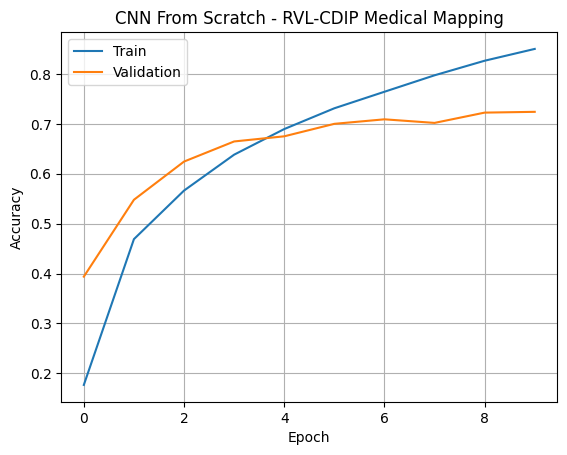

In [103]:
import matplotlib.pyplot as plt
plt.plot(train_acc_list, label="Train")
plt.plot(val_acc_list, label="Validation")
plt.title("CNN From Scratch - RVL-CDIP Medical Mapping")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

###### dataset (medical-mnist)

In [15]:
classes_med = sorted([d.name for d in MED_PATH.iterdir() if d.is_dir()])
classes_med
classes_numm=len(classes_med)
classes_numm

6

In [16]:
data = []

for c in classes_med:
    folder = MED_PATH / c
    images = list(folder.glob("*.jpeg")) 
    
    for img in images:
        data.append((str(img), c))

df_med = pd.DataFrame(data, columns=["path", "label"])
df_med.head()

,path,label
0,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
1,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
2,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
3,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
4,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT


In [17]:
encoder=LabelEncoder()

df_med["label"]=encoder.fit_transform(
df_med["label"]
)

print(
encoder.classes_
)

['AbdomenCT' 'BreastMRI' 'CXR' 'ChestCT' 'Hand' 'HeadCT']


In [12]:
from torch.utils.data import Dataset
from PIL import Image

class MedicalDataset(Dataset):

    def __init__(
        self,
        df,
        transform=None
    ):

        self.df=df.reset_index(drop=True)
        self.transform=transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self,idx):

        path=self.df.loc[
            idx,
            "path"
        ]

        label=self.df.loc[
            idx,
            "label"
        ]

        image=Image.open(
            path
        ).convert("RGB")

        if self.transform:

            image=self.transform(
                image
            )

        return image,label

In [20]:
from sklearn.model_selection import train_test_split

train_df,val_df=train_test_split(

df_med,

test_size=0.2,

stratify=df_med["label"],

random_state=42

)

In [18]:
train_dataset=MedicalDataset(
train_df,
train_transform
)

val_dataset=MedicalDataset(
val_df,
val_transform
)

from torch.utils.data import DataLoader

train_loader=DataLoader(

train_dataset,

batch_size=32,

shuffle=True

)

val_loader=DataLoader(

val_dataset,

batch_size=32,

shuffle=False

)

In [2]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [23]:
model=CNNFromScratch(8)

model=model.to(device)

In [25]:
import torch.optim as optim
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [26]:
best_acc = 0.0

for epoch in tqdm(range(10)):

    # MODE ENTRAINEMENT
    model.train()

    running_loss = 0
    correct_train = 0
    total_train = 0

    for imgs, labels in train_loader:

        imgs = imgs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        # LOSS TRAIN
        running_loss += loss.item()

        # ACC TRAIN
        preds = outputs.argmax(1)

        correct_train += (preds == labels).sum().item()

        total_train += labels.size(0)

    train_loss = running_loss / len(train_loader)

    train_acc = correct_train / total_train


    # VALIDATION
    model.eval()

    val_loss = 0

    correct = 0

    total = 0

    with torch.no_grad():

        for imgs, labels in tqdm(val_loader):

            imgs = imgs.to(device)

            labels = labels.to(device)

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(1)

            correct += (preds == labels).sum().item()

            total += labels.size(0)

    val_loss /= len(val_loader)

    val_acc = correct / total


    print(f"\nEpoch {epoch+1}/10")

    print(
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    # SAUVEGARDE MEILLEUR MODELE

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            "cnn_imagerie.pth"
        )

        print("Meilleur modèle sauvegardé")

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/369 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.0740 | Train Acc: 0.9784
Val Loss: 0.0116 | Val Acc: 0.9975
Meilleur modèle sauvegardé


  0%|          | 0/369 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 0.0248 | Train Acc: 0.9933
Val Loss: 0.0090 | Val Acc: 0.9964


...


Epoch 8/10
Train Loss: 0.0097 | Train Acc: 0.9972
Val Loss: 0.0118 | Val Acc: 0.9978


  0%|          | 0/369 [00:00<?, ?it/s]


Epoch 9/10
Train Loss: 0.0097 | Train Acc: 0.9975
Val Loss: 0.0081 | Val Acc: 0.9982


  0%|          | 0/369 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.0098 | Train Acc: 0.9973
Val Loss: 0.0041 | Val Acc: 0.9991


Nous utilisons Albumentations afin d’améliorer la robustesse du modèle et limiter l’overfitting.

Transformations utilisées :

rotations légères,
ajustement luminosité/contraste,
crops aléatoires.

Nous n’utilisons pas de flips horizontaux car cela n’a pas de sens pour des documents médicaux ou administratifs.

##### Transfer Learning — ResNet50 Feature Extraction

Nous utilisons un modèle ResNet50 pré-entraîné sur ImageNet.

In [17]:
train_transform = A.Compose([A.Resize(224,224),A.Rotate(limit=5,p=0.5),
                             A.RandomBrightnessContrast(brightness_limit=0.1,contrast_limit=0.1,p=0.5),
                             A.RandomCrop(height=200,width=200,p=0.3 ),
                             A.Resize(224,224),
                             A.Normalize(mean=(0.485,0.456,0.406),std=(0.229,0.224,0.225)),
                             ToTensorV2()])

In [18]:
val_transform = A.Compose([A.Resize(224,224),
                           A.Normalize(mean=(0.485,0.456,0.406),std=(0.229,0.224,0.225)),ToTensorV2()])

In [19]:
class DocumentDataset(Dataset):
    def __init__(self, dataframe, root_dir=None, transform=None):
        self.dataframe = dataframe
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        if self.root_dir:
            img_path = self.root_dir / self.dataframe.iloc[idx]["path"]
        else:
            img_path = self.dataframe.iloc[idx]["path"]

        label = self.dataframe.iloc[idx]["label"]

        image = Image.open(img_path).convert("RGB")
        image = np.array(image)

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, label

In [15]:
train_df_rvl, val_df_rvl = train_test_split(
    df_balanced,
    test_size=0.2,
    stratify=df_balanced["label"],
    random_state=42)

In [24]:
train_df_med,val_df_med=train_test_split(

df_med,

test_size=0.2,

stratify=df_med["label"],

random_state=42

)

In [ ]:
train_dataset_med = DocumentDataset(
    train_df_med,
    transform=train_transform
)

val_dataset_med = DocumentDataset(
    val_df_med,
    transform=val_transform
)
train_dataset_rvl = DocumentDataset(
    train_df_rvl,
    root_dir=RVL_PATH / "images",
    transform=train_transform
)

val_dataset_rvl = DocumentDataset(
    val_df_rvl,
    root_dir=RVL_PATH / "images",
    transform=val_transform
)

In [26]:
train_loader_med = DataLoader(train_dataset_med,batch_size=32,shuffle=True)
val_loader_med = DataLoader(val_dataset_med,batch_size=32,shuffle=False)
train_loader_rvl = DataLoader(train_dataset_rvl,batch_size=32,shuffle=True)
val_loader_rvl = DataLoader(val_dataset_rvl,batch_size=32,shuffle=False)

In [120]:
# ====================================================
# RESNET50 FEATURE EXTRACTION
# ====================================================

class ResNetFeatureExtractor(pl.LightningModule):

    def __init__(self, num_classes):

        super().__init__()

        # Charger ResNet50 pré-entraîné
        self.model = resnet50(pretrained=True)

        # Geler toutes les couches
        for param in self.model.parameters():
            param.requires_grad = False

        # Remplacer la couche finale
        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )

        # Fonction de perte
        self.criterion = nn.CrossEntropyLoss()

    # ------------------------------------------------
    # Forward
    # ------------------------------------------------

    def forward(self, x):

        return self.model(x)

    # ------------------------------------------------
    # Training
    # ------------------------------------------------

    def training_step(self, batch, batch_idx):

        images, labels = batch

        outputs = self(images)

        loss = self.criterion(outputs, labels)

        preds = outputs.argmax(dim=1)

        acc = (preds == labels).float().mean()

        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)

        return loss

    # ------------------------------------------------
    # Validation
    # ------------------------------------------------

    def validation_step(self, batch, batch_idx):

        images, labels = batch

        outputs = self(images)

        loss = self.criterion(outputs, labels)

        preds = outputs.argmax(dim=1)

        acc = (preds == labels).float().mean()

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

    # ------------------------------------------------
    # Optimizer
    # ------------------------------------------------

    def configure_optimizers(self):

        optimizer = torch.optim.Adam(
            self.model.fc.parameters(),
            lr=1e-3
        )

        return optimizer

In [121]:
resnet_model_rvl = ResNetFeatureExtractor(
    num_classes=num_classes
)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [124]:
resnet_model_med = ResNetFeatureExtractor(
    num_classes=num_classes
)

In [88]:
checkpoint_callback = ModelCheckpoint(monitor="val_acc",mode="max",save_top_k=1,filename="best_resnet_feature")

In [125]:
trainer1 = pl.Trainer(max_epochs=10,accelerator="gpu",devices=1,callbacks=[checkpoint_callback])
trainer2 = pl.Trainer(max_epochs=10,accelerator="gpu",devices=1,callbacks=[checkpoint_callback])

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [126]:
trainer1.fit(resnet_model_rvl,train_loader_rvl,val_loader_rvl)
trainer2.fit(resnet_model_med,train_loader_med,val_loader_med)

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /kaggle/working/lightning_logs/version_1/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ ResNet           │ 23.5 M │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 16.4 K                                                                                           
Non-trainable params: 23.5 M                                                                                       
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 152                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ ResNet           │ 23.5 M │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 16.4 K                                                                                           
Non-trainable params: 23.5 M                                                                                       
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 152                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=10` reached.


In [128]:
common = set(train_df_med["path"]).intersection(
    set(val_df_med["path"])
)

print(len(common))

0


In [127]:
torch.save(resnet_model_rvl.state_dict(),"resnet_feature_rvl.pt")
torch.save(resnet_model_med.state_dict(),"resnet_feature_med.pt")

##### Fine-Tuning complet — ResNet50

Toutes les couches sont réentraînées avec un faible learning rate afin d’adapter complètement le modèle au dataset documentaire.

In [22]:
class ResNetFineTuning(pl.LightningModule):

    def __init__(self, num_classes):
        super().__init__()

        # modèle pré-entraîné
        self.model = models.resnet50(pretrained=True)

        # remplacer la dernière couche
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

        for param in self.model.parameters():
            param.requires_grad = True

        self.criterion = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        y = y.long()

        logits = self(x)
        loss = self.criterion(logits, y)

        acc = (logits.argmax(1) == y).float().mean()

        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)

        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = y.long()

        logits = self(x)
        loss = self.criterion(logits, y)

        acc = (logits.argmax(1) == y).float().mean()

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

    def configure_optimizers(self):
        
        optimizer = torch.optim.Adam(
            self.model.parameters(),
            lr=1e-5
        )
        return optimizer

In [23]:
checkpoint_callback = ModelCheckpoint(monitor="val_acc",mode="max",save_top_k=1,filename="best_resnet_feature")

In [24]:
trainer_rvl = pl.Trainer(max_epochs=10,accelerator="gpu",devices=1,callbacks=[checkpoint_callback])
trainer_med = pl.Trainer(max_epochs=10,accelerator="gpu",devices=1,callbacks=[checkpoint_callback])


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [25]:
resnet_fineT_model_rvl = ResNetFineTuning(num_classes=num_classes)
resnet_fineT_model_med = ResNetFineTuning(num_classes=classes_numm)

trainer_rvl.fit(resnet_fineT_model_rvl,train_loader_rvl,val_loader_rvl)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s] 
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ ResNet           │ 23.5 M │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 23.5 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 152                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=10` reached.


In [26]:
trainer_med.fit(resnet_fineT_model_med,train_loader_med,val_loader_med)

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /kaggle/working/lightning_logs/version_0/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ ResNet           │ 23.5 M │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 23.5 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 152                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=10` reached.


In [28]:
torch.save(resnet_fineT_model_rvl.state_dict(),"resnet_fineT_model_rvl.pt")
torch.save(resnet_fineT_model_med.state_dict(),"resnet_fineT_model_med.pt")

In [29]:
import os

os.listdir("/kaggle/working/lightning_logs")

['version_0', 'version_1']

In [35]:
import os

print(os.listdir("/kaggle/input/datasets/hibachach/resnet"))

['resnet', 'data-ocr-result']


In [29]:
model1 = models.resnet50(weights=None)
model2 = models.resnet50(weights=None)
model3 = models.resnet50(weights=None)
model4 = models.resnet50(weights=None)
model5 = models.resnet50(weights=None)
model6 = models.resnet50(weights=None)

# adapter les sorties si besoin (ex: 8 classes)
model1.fc = torch.nn.Linear(2048, 8)
model2.fc = torch.nn.Linear(2048, 8)
model3.fc = torch.nn.Linear(2048, 6)
model4.fc = torch.nn.Linear(2048, 8)

# -------------------
# LOAD CHECKPOINTS
# -------------------
checkpoint1 = torch.load("/kaggle/input/datasets/hibabb/resenetttt/resnet_feature_rvl (1).pt")
checkpoint2 = torch.load("/kaggle/input/datasets/hibabb/resenetttt/resnet_feature_med (1).pt")
checkpoint3 = torch.load("/kaggle/input/datasets/hibabb/resenetttt/resnet_fineT_model_med (1).pt")
checkpoint4 = torch.load("/kaggle/input/datasets/hibabb/resenetttt/resnet_fineT_model_rvl (1).pt")


# -------------------
# FUNCTION CLEAN
# -------------------
def load_model(model, checkpoint):
    new_state_dict = {}

    for k, v in checkpoint.items():
        k = k.replace("model.", "")  # important
        new_state_dict[k] = v

    model.load_state_dict(new_state_dict, strict=False)
    model.eval()
    model.cuda()
    return model


# -------------------
# APPLY
# -------------------
model1 = load_model(model1, checkpoint1)
model2 = load_model(model2, checkpoint2)
model3 = load_model(model3, checkpoint3)
model4 = load_model(model4, checkpoint4)

In [27]:
y_true = []
y_pred = []
for images, labels in val_loader_rvl:
    images = images.cuda()
    labels = labels.cuda()

    outputs = model1(images)
    preds = torch.argmax(outputs, dim=1)

    y_true.extend(labels.cpu().numpy())
    y_pred.extend(preds.cpu().numpy())

In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.56      0.64      0.59       400
           1       0.47      0.66      0.54       400
           2       0.51      0.42      0.46       400
           3       0.68      0.36      0.47       400
           4       0.84      0.86      0.85       400
           5       0.80      0.83      0.81       400
           6       0.52      0.57      0.55       400
           7       0.50      0.47      0.48       400

    accuracy                           0.60      3200
   macro avg       0.61      0.60      0.59      3200
weighted avg       0.61      0.60      0.59      3200



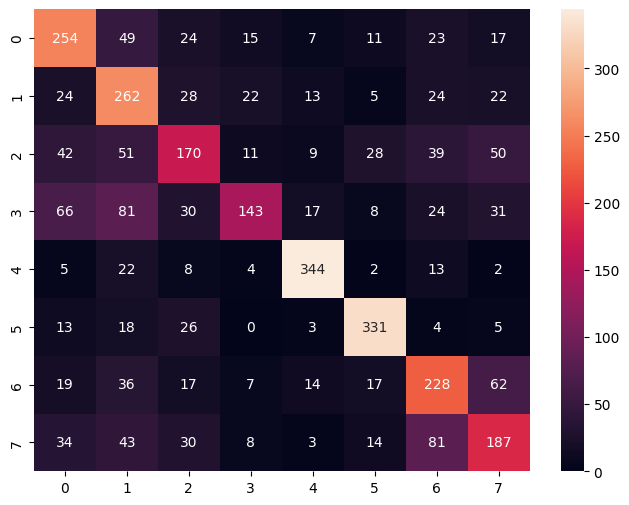

In [29]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

              precision    recall  f1-score   support

           0       0.80      0.81      0.81       400
           1       0.74      0.77      0.75       400
           2       0.75      0.69      0.72       400
           3       0.70      0.62      0.66       400
           4       0.89      0.94      0.92       400
           5       0.95      0.88      0.91       400
           6       0.76      0.83      0.79       400
           7       0.80      0.84      0.82       400

    accuracy                           0.80      3200
   macro avg       0.80      0.80      0.80      3200
weighted avg       0.80      0.80      0.80      3200



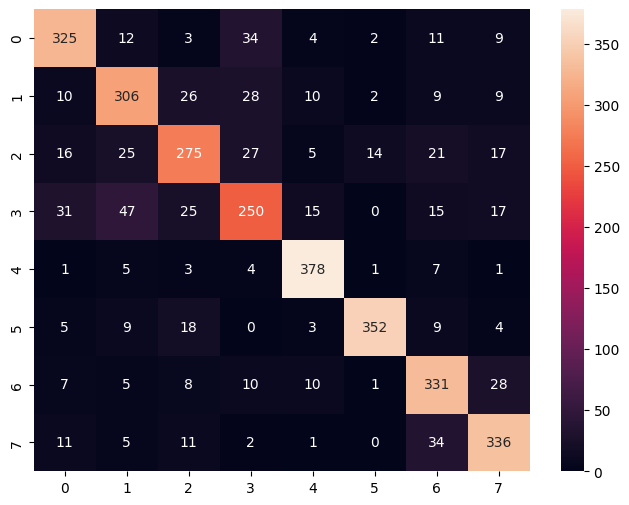

In [30]:
y_true = []
y_pred = []
for images, labels in val_loader_rvl:
    images = images.cuda()
    labels = labels.cuda()

    outputs = model4(images)
    preds = torch.argmax(outputs, dim=1)

    y_true.extend(labels.cpu().numpy())
    y_pred.extend(preds.cpu().numpy())
print(classification_report(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000
           1       1.00      1.00      1.00      1791
           2       1.00      1.00      1.00      2000
           3       1.00      1.00      1.00      2000
           4       1.00      1.00      1.00      2000
           5       1.00      1.00      1.00      2000

    accuracy                           1.00     11791
   macro avg       1.00      1.00      1.00     11791
weighted avg       1.00      1.00      1.00     11791



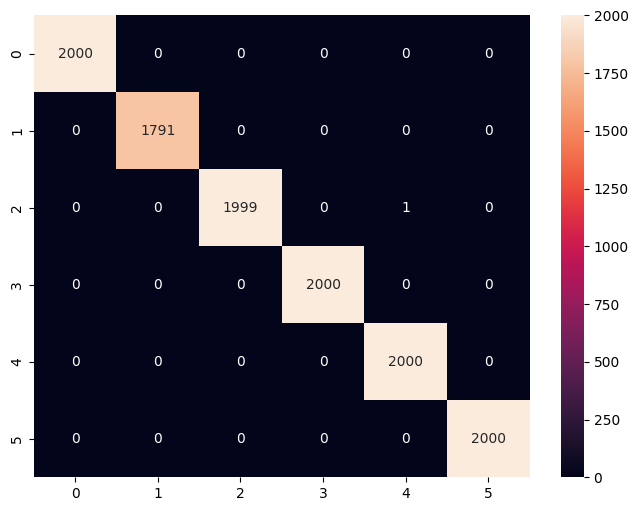

In [31]:
y_true = []
y_pred = []
for images, labels in val_loader_med:
    images = images.cuda()
    labels = labels.cuda()

    outputs = model2(images)
    preds = torch.argmax(outputs, dim=1)

    y_true.extend(labels.cpu().numpy())
    y_pred.extend(preds.cpu().numpy())
print(classification_report(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000
           1       1.00      1.00      1.00      1791
           2       1.00      1.00      1.00      2000
           3       1.00      1.00      1.00      2000
           4       1.00      1.00      1.00      2000
           5       1.00      1.00      1.00      2000

    accuracy                           1.00     11791
   macro avg       1.00      1.00      1.00     11791
weighted avg       1.00      1.00      1.00     11791



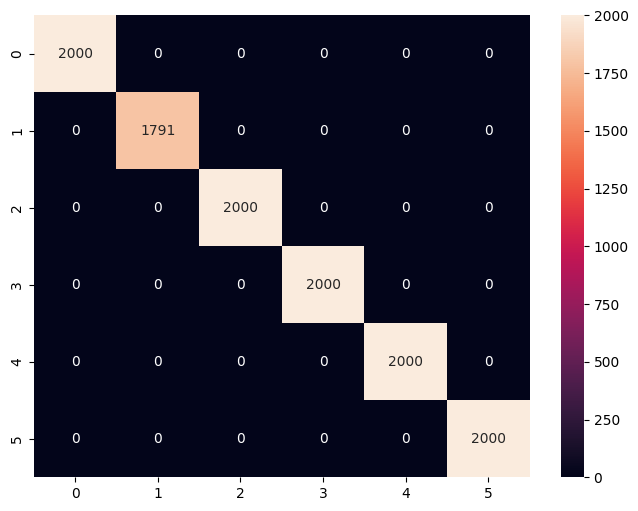

In [32]:
y_true = []
y_pred = []
for images, labels in val_loader_med:
    images = images.cuda()
    labels = labels.cuda()

    outputs = model3(images)
    preds = torch.argmax(outputs, dim=1)

    y_true.extend(labels.cpu().numpy())
    y_pred.extend(preds.cpu().numpy())
print(classification_report(y_true, y_pred))
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

,Accuracy,F1 Macro,F1 Weighted
Modèle,,,
ResNet50 Fine-Tuning (Med),100.0%,100.0%,100.0%
ResNet50 Feature Extraction (Med),100.0%,100.0%,100.0%
ResNet50 Fine-Tuning (RVL),79.8%,79.7%,79.7%
ResNet50 Feature Extraction (RVL),60.0%,59.5%,59.5%


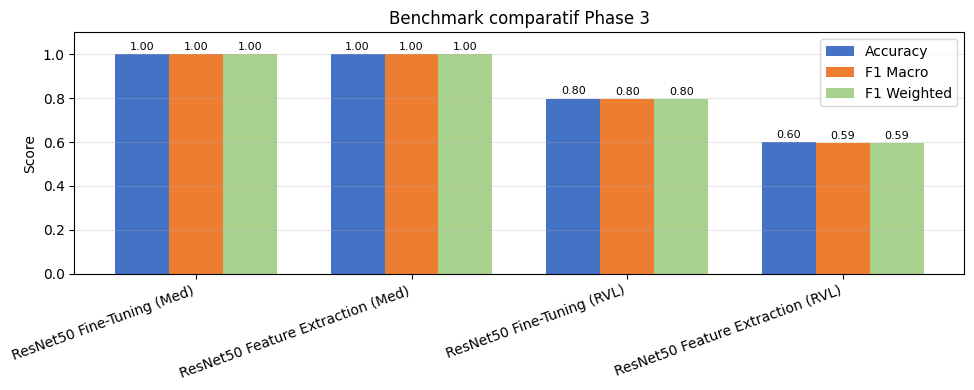


Note : model1 et model4 évalués sur val_loader_rvl (RVL Medical)
       model2 et model3 évalués sur val_loader_med (Medical MNIST)
       Les deux datasets n'étant pas identiques, la comparaison est indicative.


In [30]:
def get_scores(model, loader, model_name):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.cuda()
            preds  = model(images).argmax(dim=1).cpu().numpy()
            y_pred.extend(preds)
            y_true.extend(labels.cpu().numpy())
    return {
        "Modèle":       model_name,
        "Accuracy":     round(accuracy_score(y_true, y_pred), 3),
        "F1 Macro":     round(f1_score(y_true, y_pred, average="macro",    zero_division=0), 3),
        "F1 Weighted":  round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 3),
    }

# model1 = ResNet Feature Extraction (RVL)   → val_loader_rvl
# model2 = ResNet Feature Extraction (Med)   → val_loader_med
# model3 = CNN Scratch (Med)                 → val_loader_med
# model4 = ResNet Fine-Tuning (RVL)          → val_loader_rvl

results = [
    get_scores(model1, val_loader_rvl, "ResNet50 Feature Extraction (RVL)"),
    get_scores(model4, val_loader_rvl, "ResNet50 Fine-Tuning (RVL)"),
    get_scores(model2, val_loader_med, "ResNet50 Feature Extraction (Med)"),
    get_scores(model3, val_loader_med, "ResNet50 Fine-Tuning (Med)"),
]


df_bench = pd.DataFrame(results).set_index("Modèle")
df_bench = df_bench.sort_values("F1 Macro", ascending=False)

# Tableau stylisé
display(
    df_bench.style
    .format("{:.1%}")
    .highlight_max(axis=0, color="#c6efce")
    .highlight_min(axis=0, color="#ffc7ce")
    .set_caption("Benchmark Phase 3 — modèles déjà entraînés")
)

# Graphe
fig, ax = plt.subplots(figsize=(10, 4))
x     = np.arange(len(df_bench))
width = 0.25

b1 = ax.bar(x - width, df_bench["Accuracy"],    width, label="Accuracy",    color="#4472C4")
b2 = ax.bar(x,         df_bench["F1 Macro"],    width, label="F1 Macro",    color="#ED7D31")
b3 = ax.bar(x + width, df_bench["F1 Weighted"], width, label="F1 Weighted", color="#A9D18E")

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f"{bar.get_height():.2f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(df_bench.index, rotation=20, ha="right")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Benchmark comparatif Phase 3")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("benchmark_phase3.png", dpi=150)
plt.show()

print("\nNote : model1 et model4 évalués sur val_loader_rvl (RVL Medical)")
print("       model2 et model3 évalués sur val_loader_med (Medical MNIST)")
print("       Les deux datasets n'étant pas identiques, la comparaison est indicative.")

 ANALYSE D'ERREURS — RVL-Medical (ResNet50 Fine-Tuning)


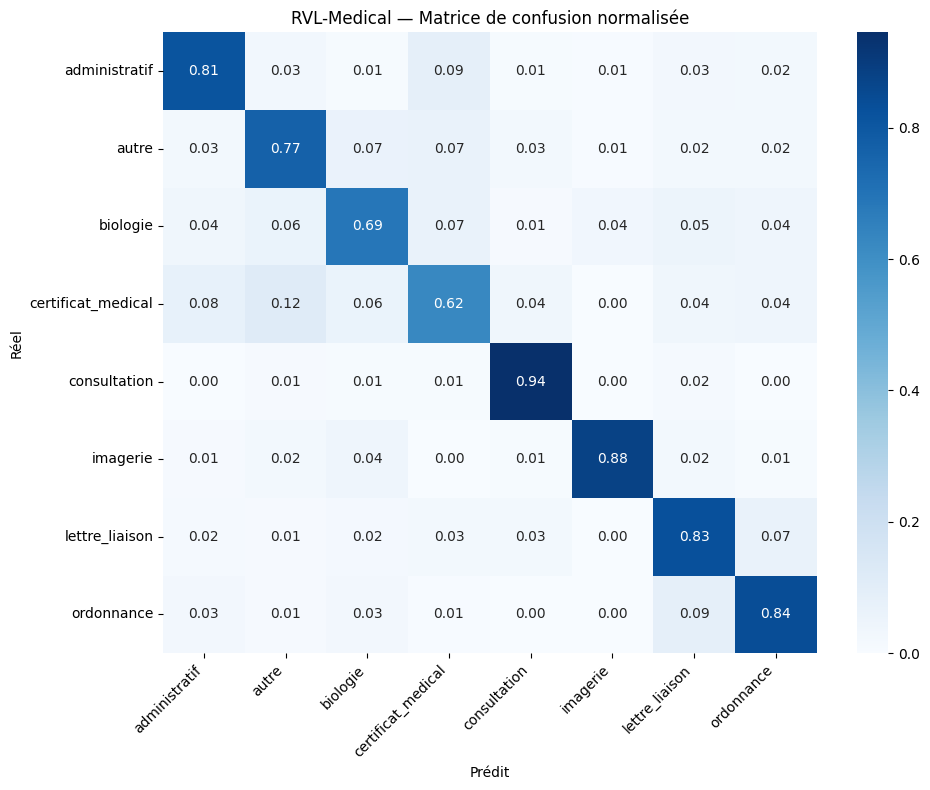


⚠️  Top confusions (vrais → prédits, taux > 10%) :
   certificat_medical        → autre                      (12%)

────────────────────────────────────────────────────────────
 RVL-Medical — F1 par classe
────────────────────────────────────────────────────────────
                    precision  recall  f1-score  support
administratif        0.800493  0.8125  0.806452      400
autre                0.739130  0.7650  0.751843      400
biologie             0.745257  0.6875  0.715215      400
certificat_medical   0.704225  0.6250  0.662252      400
consultation         0.887324  0.9450  0.915254      400
imagerie             0.946237  0.8800  0.911917      400
lettre_liaison       0.757437  0.8275  0.790920      400
ordonnance           0.798100  0.8400  0.818514      400


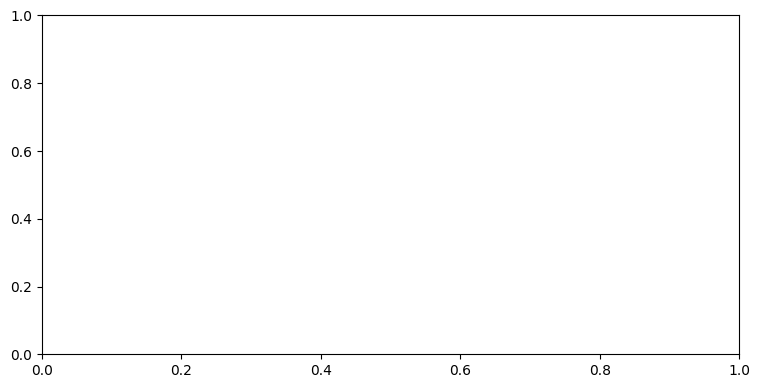

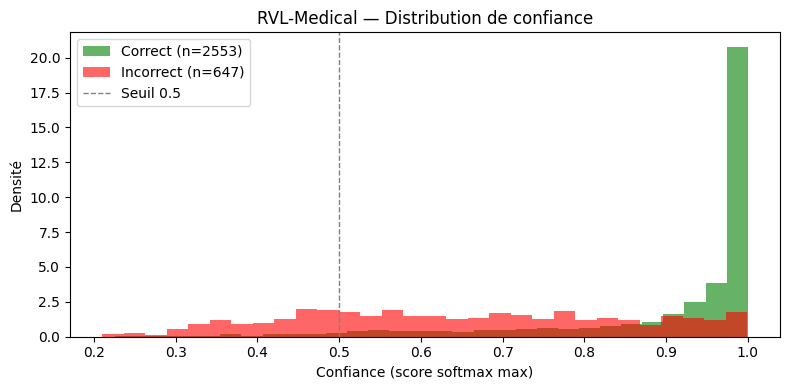


📊 Confiance moyenne — correct : 0.904 | incorrect : 0.648
   Erreurs avec confiance > 80% (erreurs «silencieuses») : 25.8%

🔍 647 erreurs au total | affichage des 30 plus confiantes


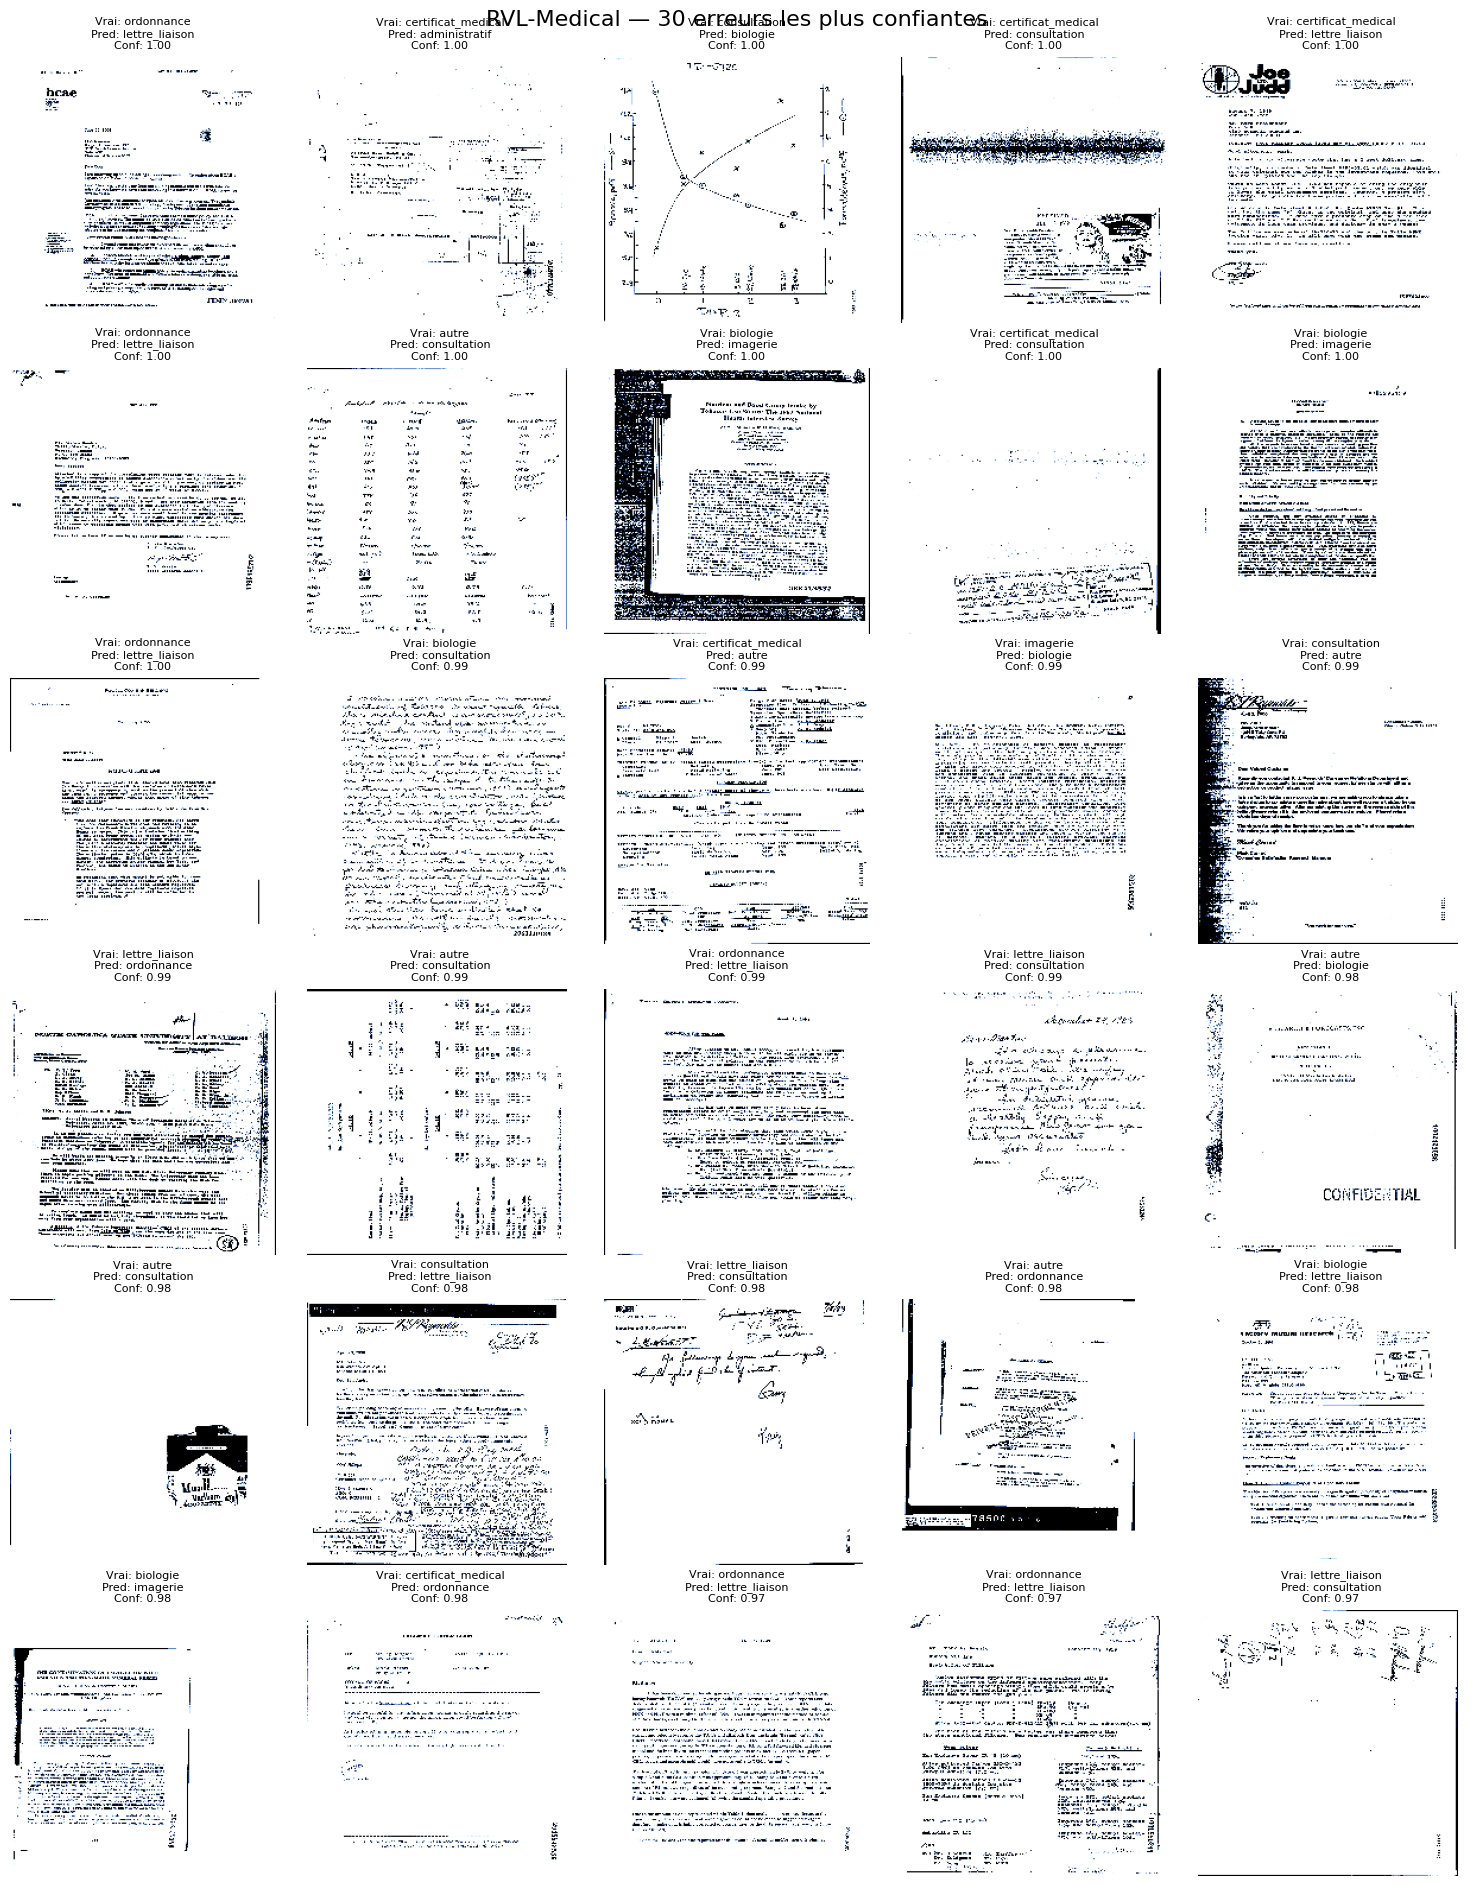


════════════════════════════════════════════════════════════
 RÉSUMÉ ANALYSE D'ERREURS
════════════════════════════════════════════════════════════
 Total samples   : 3200
 Erreurs         : 647  (20.2%)
 Accuracy globale: 0.798

 Top 5 paires d'erreur (Réel → Prédit) :
   certificat_medical        → autre                     :   47 fois | conf moy: 0.62
   administratif             → certificat_medical        :   34 fois | conf moy: 0.63
   ordonnance                → lettre_liaison            :   34 fois | conf moy: 0.75
   certificat_medical        → administratif             :   31 fois | conf moy: 0.67
   autre                     → certificat_medical        :   28 fois | conf moy: 0.69

 Classes les plus difficiles (recall < 0.70) :
   biologie                       recall = 0.69
   certificat_medical             recall = 0.62

 ANALYSE D'ERREURS — Medical MNIST (ResNet50 Fine-Tuning)


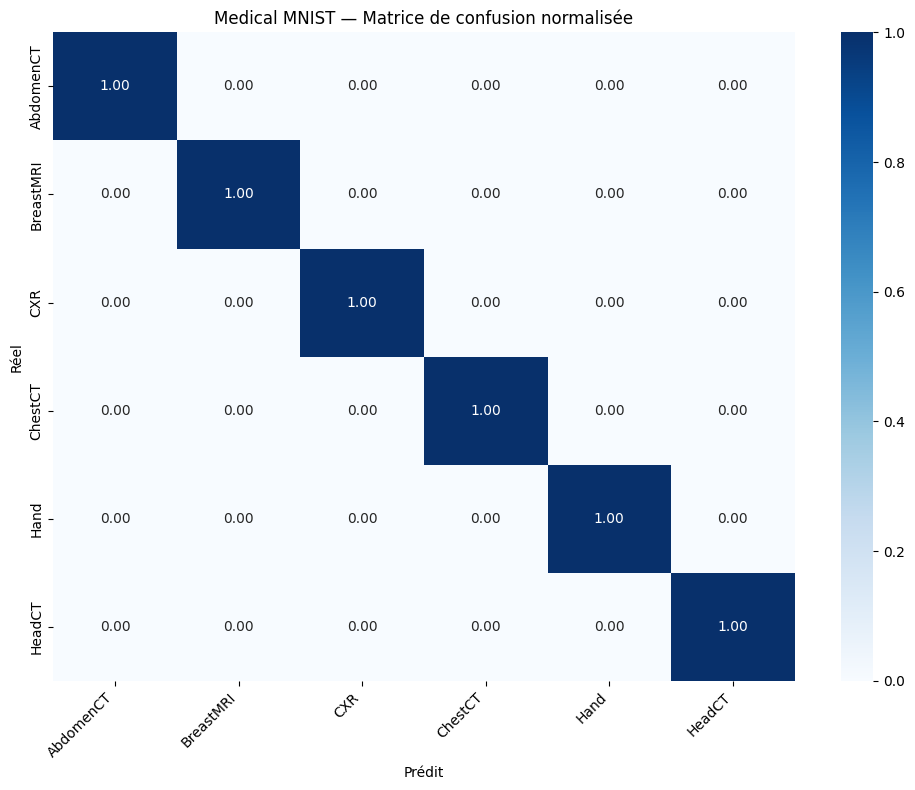


⚠️  Top confusions (vrais → prédits, taux > 10%) :

────────────────────────────────────────────────────────────
 Medical MNIST — F1 par classe
────────────────────────────────────────────────────────────
           precision  recall  f1-score  support
AbdomenCT        1.0     1.0       1.0     2000
BreastMRI        1.0     1.0       1.0     1791
CXR              1.0     1.0       1.0     2000
ChestCT          1.0     1.0       1.0     2000
Hand             1.0     1.0       1.0     2000
HeadCT           1.0     1.0       1.0     2000


/usr/local/lib/python3.12/dist-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


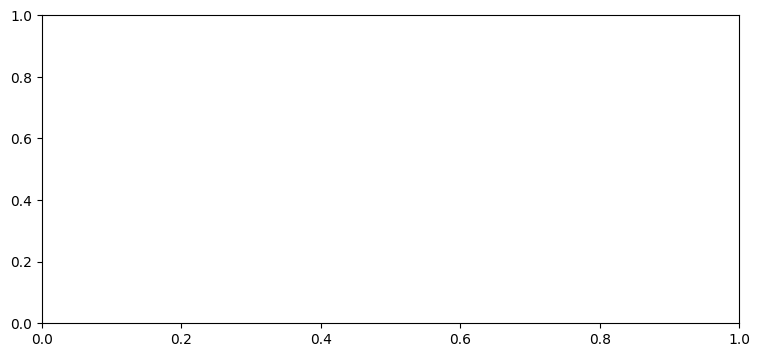

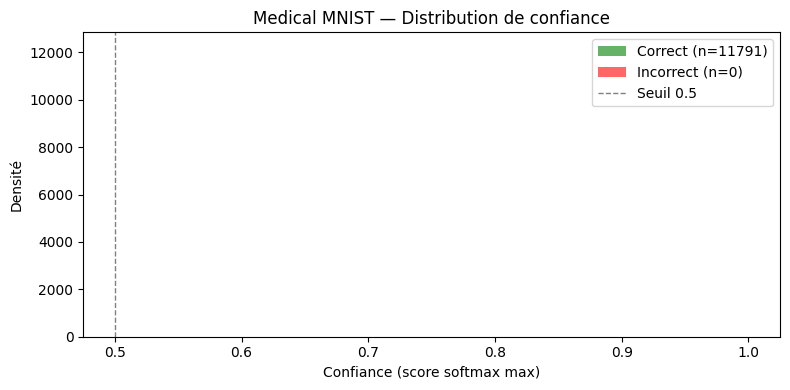


📊 Confiance moyenne — correct : 1.000 | incorrect : nan
   Erreurs avec confiance > 80% (erreurs «silencieuses») : nan%

✅ Le modèle a correctement classé tous les exemples.

════════════════════════════════════════════════════════════
 RÉSUMÉ ANALYSE D'ERREURS
════════════════════════════════════════════════════════════
 Total samples   : 11791
 Erreurs         : 0  (0.0%)
 Accuracy globale: 1.000

 Top 5 paires d'erreur (Réel → Prédit) :

 Classes les plus difficiles (recall < 0.70) :




/tmp/ipykernel_58/353986141.py:205: RuntimeWarning: Mean of empty slice
  print(f"\n📊 Confiance moyenne — correct : {correct_conf.mean():.3f} | incorrect : {incorrect_conf.mean():.3f}")
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_58/353986141.py:206: RuntimeWarning: Mean of empty slice
  pct_high_conf_errors = (incorrect_conf > 0.80).mean() * 100
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,Modèle,Accuracy,F1 Macro,F1 Weighted,Nb erreurs,% erreurs
0,ResNet50 Fine-Tuning — RVL-Medical,79.8%,79.7%,79.7%,647,20.2%
1,ResNet50 Fine-Tuning — Medical MNIST,100.0%,100.0%,100.0%,0,0.0%


In [32]:
# ============================================================
# ANALYSE D'ERREURS CIBLÉE — PHASE 3
# À coller à la fin du notebook, après le benchmark
# Fonctionne pour RVL-Medical (model4) et Medical MNIST (model3)
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
import math

# ─────────────────────────────────────────────────────────────
# 0. UTILITAIRE : collecter prédictions + images + scores
# ─────────────────────────────────────────────────────────────

def collect_predictions(model, loader, class_names, device="cuda"):
    """
    Parcourt le loader, retourne un dict avec :
      - y_true, y_pred : listes d'indices
      - confidences    : score max (softmax) pour chaque sample
      - images         : tenseurs CPU (non-normalisés pour affichage)
    """
    model.eval()
    y_true, y_pred, confidences, all_images = [], [], [], []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs_dev = imgs.to(device)
            logits   = model(imgs_dev)
            probs    = torch.softmax(logits, dim=1)
            conf, pred = probs.max(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(pred.cpu().numpy())
            confidences.extend(conf.cpu().numpy())
            all_images.extend(imgs.cpu())          # garde les tenseurs CPU

    return {
        "y_true":      np.array(y_true),
        "y_pred":      np.array(y_pred),
        "conf":        np.array(confidences),
        "images":      all_images,
        "class_names": class_names,
    }


# ─────────────────────────────────────────────────────────────
# 1. MATRICE DE CONFUSION NORMALISÉE
# ─────────────────────────────────────────────────────────────

def plot_confusion_matrix(res, title="Matrice de confusion normalisée"):
    y_true, y_pred   = res["y_true"], res["y_pred"]
    class_names      = res["class_names"]

    cm = confusion_matrix(y_true, y_pred, normalize="true")

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt=".2f",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # Résumé textuel des confusions les plus fréquentes
    print("\n⚠️  Top confusions (vrais → prédits, taux > 10%) :")
    for i, true_cls in enumerate(class_names):
        for j, pred_cls in enumerate(class_names):
            if i != j and cm[i, j] > 0.10:
                print(f"   {true_cls:25s} → {pred_cls:25s}  ({cm[i,j]:.0%})")


# ─────────────────────────────────────────────────────────────
# 2. RAPPORT PAR CLASSE + VISUALISATION
# ─────────────────────────────────────────────────────────────

def plot_per_class_f1(res, title="F1 par classe"):
    y_true, y_pred = res["y_true"], res["y_pred"]
    class_names    = res["class_names"]

    report = classification_report(
        y_true, y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    df_report = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
    df_report["support"] = df_report["support"].astype(int)
    print(f"\n{'─'*60}")
    print(f" {title}")
    print(f"{'─'*60}")
    print(df_report.to_string())

    # Graphe barres horizontales
    fig, ax = plt.subplots(figsize=(9, max(4, len(class_names) * 0.55)))
    y_pos = range(len(class_names))
    f
# ─────────────────────────────────────────────────────────────
# 3. GALERIE DES ERREURS : images mal classées avec confiance
# ─────────────────────────────────────────────────────────────
def show_error_gallery(res, n=30, title="Erreurs les plus confiantes"):

    y_true      = np.array(res["y_true"])
    y_pred      = np.array(res["y_pred"])
    confidences = np.array(res["conf"])
    images      = res["images"]
    class_names = res["class_names"]

    # indices des erreurs
    error_idx = np.where(y_true != y_pred)[0]

    # CAS IMPORTANT : aucune erreur
    if len(error_idx) == 0:
        print("\n✅ Le modèle a correctement classé tous les exemples.")
        return

    print(f"\n🔍 {len(error_idx)} erreurs au total | affichage des {min(n, len(error_idx))} plus confiantes")

    # tri décroissant par confiance
    sorted_errors = error_idx[
        np.argsort(confidences[error_idx])[::-1]
    ]

    sorted_errors = sorted_errors[:n]

    cols = 5
    rows = math.ceil(len(sorted_errors) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * 3, rows * 3.2)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, sorted_errors):

        img = images[idx]

        if torch.is_tensor(img):
            img = img.permute(1, 2, 0).numpy()

        img = np.clip(img, 0, 1)

        if img.shape[-1] == 1:
            ax.imshow(img.squeeze(), cmap="gray")
        else:
            ax.imshow(img)

        true_label = class_names[y_true[idx]]
        pred_label = class_names[y_pred[idx]]
        conf       = confidences[idx]

        ax.set_title(
            f"Vrai: {true_label}\n"
            f"Pred: {pred_label}\n"
            f"Conf: {conf:.2f}",
            fontsize=8
        )

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()
# ─────────────────────────────────────────────────────────────
# 4. DISTRIBUTION DE CONFIANCE : correct vs incorrect
# ─────────────────────────────────────────────────────────────

def plot_confidence_distribution(res, title="Distribution de confiance"):
    y_true, y_pred = res["y_true"], res["y_pred"]
    conf           = res["conf"]

    correct_conf   = conf[y_true == y_pred]
    incorrect_conf = conf[y_true != y_pred]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(correct_conf,   bins=30, alpha=0.6, color="green",  label=f"Correct (n={len(correct_conf)})",   density=True)
    ax.hist(incorrect_conf, bins=30, alpha=0.6, color="red",    label=f"Incorrect (n={len(incorrect_conf)})", density=True)

    ax.axvline(0.5, color="grey", linestyle="--", linewidth=1, label="Seuil 0.5")
    ax.set_xlabel("Confiance (score softmax max)")
    ax.set_ylabel("Densité")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Statistiques rapides
    print(f"\n📊 Confiance moyenne — correct : {correct_conf.mean():.3f} | incorrect : {incorrect_conf.mean():.3f}")
    pct_high_conf_errors = (incorrect_conf > 0.80).mean() * 100
    print(f"   Erreurs avec confiance > 80% (erreurs «silencieuses») : {pct_high_conf_errors:.1f}%")


# ─────────────────────────────────────────────────────────────
# 5. RÉSUMÉ ÉCRIT : les patterns d'erreurs principaux
# ─────────────────────────────────────────────────────────────

def print_error_summary(res, top_k=5):
    y_true, y_pred = res["y_true"], res["y_pred"]
    conf           = res["conf"]
    class_names    = res["class_names"]

    error_mask = y_true != y_pred
    n_errors   = error_mask.sum()
    n_total    = len(y_true)

    print(f"\n{'═'*60}")
    print(f" RÉSUMÉ ANALYSE D'ERREURS")
    print(f"{'═'*60}")
    print(f" Total samples   : {n_total}")
    print(f" Erreurs         : {n_errors}  ({n_errors/n_total:.1%})")
    print(f" Accuracy globale: {(n_total - n_errors)/n_total:.3f}")

    # Paires d'erreur les plus fréquentes
    print(f"\n Top {top_k} paires d'erreur (Réel → Prédit) :")
    from collections import Counter
    pairs = Counter(zip(y_true[error_mask], y_pred[error_mask]))
    for (t, p), count in pairs.most_common(top_k):
        avg_conf = conf[(y_true == t) & (y_pred == p)].mean()
        print(f"   {class_names[t]:25s} → {class_names[p]:25s} : {count:4d} fois | conf moy: {avg_conf:.2f}")

    # Classes avec le plus d'erreurs
    print(f"\n Classes les plus difficiles (recall < 0.70) :")
    from sklearn.metrics import recall_score
    recalls = recall_score(y_true, y_pred, average=None, zero_division=0)
    for i, (cls, rec) in enumerate(zip(class_names, recalls)):
        if rec < 0.70:
            print(f"   {cls:30s} recall = {rec:.2f}")


# ─────────────────────────────────────────────────────────────
# 6. LANCEMENT — RVL (model4 = meilleur sur RVL) 
# ─────────────────────────────────────────────────────────────

# Classes RVL après mapping projet (ordre LabelEncoder — à adapter si différent)
rvl_class_names = sorted([
    "administratif", "autre", "biologie",
    "certificat_medical", "consultation",
    "imagerie", "lettre_liaison", "ordonnance"
])

print("=" * 60)
print(" ANALYSE D'ERREURS — RVL-Medical (ResNet50 Fine-Tuning)")
print("=" * 60)

res_rvl = collect_predictions(model4, val_loader_rvl, rvl_class_names, device="cuda")

plot_confusion_matrix(res_rvl,      title="RVL-Medical — Matrice de confusion normalisée")
df_rvl = plot_per_class_f1(res_rvl, title="RVL-Medical — F1 par classe")
plot_confidence_distribution(res_rvl, title="RVL-Medical — Distribution de confiance")
show_error_gallery(res_rvl, n=30,   title="RVL-Medical — 30 erreurs les plus confiantes")
print_error_summary(res_rvl)


# ─────────────────────────────────────────────────────────────
# 7. LANCEMENT — Medical MNIST (model3 = meilleur sur Med)
#    Adapter med_class_names selon encoder.classes_ de ton notebook
# ─────────────────────────────────────────────────────────────

# ⚠️ Remplacer par : list(encoder.classes_) si tu as l'encoder en mémoire
med_class_names = sorted([
    "AbdomenCT", "BreastMRI", "ChestCT",
    "CXR", "Hand", "HeadCT"
])

print("\n" + "=" * 60)
print(" ANALYSE D'ERREURS — Medical MNIST (ResNet50 Fine-Tuning)")
print("=" * 60)

res_med = collect_predictions(model3, val_loader_med, med_class_names, device="cuda")

plot_confusion_matrix(res_med,      title="Medical MNIST — Matrice de confusion normalisée")
df_med = plot_per_class_f1(res_med, title="Medical MNIST — F1 par classe")
plot_confidence_distribution(res_med, title="Medical MNIST — Distribution de confiance")
show_error_gallery(res_med, n=30,   title="Medical MNIST — 30 erreurs les plus confiantes")
print_error_summary(res_med)


# ─────────────────────────────────────────────────────────────
# 8. TABLEAU RÉCAPITULATIF FINAL (à inclure dans le rapport)
# ─────────────────────────────────────────────────────────────

from sklearn.metrics import f1_score, accuracy_score

def summary_row(res, model_name):
    yt, yp = res["y_true"], res["y_pred"]
    return {
        "Modèle":       model_name,
        "Accuracy":     round(accuracy_score(yt, yp), 3),
        "F1 Macro":     round(f1_score(yt, yp, average="macro",    zero_division=0), 3),
        "F1 Weighted":  round(f1_score(yt, yp, average="weighted", zero_division=0), 3),
        "Nb erreurs":   int((yt != yp).sum()),
        "% erreurs":    f"{(yt != yp).mean():.1%}",
    }

df_final = pd.DataFrame([
    summary_row(res_rvl, "ResNet50 Fine-Tuning — RVL-Medical"),
    summary_row(res_med, "ResNet50 Fine-Tuning — Medical MNIST"),
])
print("\n")
display(
    df_final.style
    .format({"Accuracy": "{:.1%}", "F1 Macro": "{:.1%}", "F1 Weighted": "{:.1%}"})
    .highlight_max(subset=["F1 Macro"], color="#c6efce")
    .set_caption("Synthèse analyse d'erreurs — meilleurs modèles Phase 3")
)

##### Approche multimodale 

In [20]:
df = pd.read_csv("/kaggle/input/datasets/hibabb/ocrresultat/ocr_results (6).csv")

In [21]:
df

,Unnamed: 0,image_path,text
0,0,imagesj/j/u/j/juj25a00/528850775+-0776.tif,52885 0775\n\n \n\n \n\n \n\n \n\n \n\n \n\n \...
1,1,imagesy/y/h/k/yhk36c00/2078311626.tif,"2078311628:\n\n \n\nTo: Ci ) Mary; Cexcazo,..."
2,2,imagest/t/k/z/tkz16c00/2083319124.tif,\n\nhow's Friday at 4:007\n\nCarolyn Lewy\nYo...
3,3,imagesl/l/r/f/lrf20c00/2085785866.tif,"2085785866\n\nPabst, Joanne\n\nFrom: Beriind, ..."
4,4,imagesh/h/k/w/hkw72a00/528015544+-5544.tif,"From: Osmon, Greg\nTo: Smith, Mark D.\nce:\nBC..."
...,...,...,...
15995,15995,imagesq/q/e/e/qee87e00/2504062214.tif,"\n\nPHILIP MORRIS INTERNATIONALING, __ INTER-..."
15996,15996,imagese/e/e/h/eeh36e00/2046262296.tif,BHILIP MORRIS MANAGEMENT CORP. INTER-OFFICE CO...
15997,15997,imagesl/l/c/a/lca35f00/0060219178.tif,\n\n \n\nTHE As Memorandum\n= AMERICAN ” t\nf...
15998,15998,imagesy/y/g/x/ygx32e00/2504011052.tif,te\n\nobec:\n\n“PHILIP MORRIS ASIA INCORPORATE...


In [22]:
df_labels = df_rvl[["path", "project_class"]]
df = df.merge(
    df_labels,
    left_on="image_path",
    right_on="path"
)
df.shape

(16000, 5)

In [23]:
df

,Unnamed: 0,image_path,text,path,project_class
0,0,imagesj/j/u/j/juj25a00/528850775+-0776.tif,52885 0775\n\n \n\n \n\n \n\n \n\n \n\n \n\n \...,imagesj/j/u/j/juj25a00/528850775+-0776.tif,administratif
1,1,imagesy/y/h/k/yhk36c00/2078311626.tif,"2078311628:\n\n \n\nTo: Ci ) Mary; Cexcazo,...",imagesy/y/h/k/yhk36c00/2078311626.tif,administratif
2,2,imagest/t/k/z/tkz16c00/2083319124.tif,\n\nhow's Friday at 4:007\n\nCarolyn Lewy\nYo...,imagest/t/k/z/tkz16c00/2083319124.tif,administratif
3,3,imagesl/l/r/f/lrf20c00/2085785866.tif,"2085785866\n\nPabst, Joanne\n\nFrom: Beriind, ...",imagesl/l/r/f/lrf20c00/2085785866.tif,administratif
4,4,imagesh/h/k/w/hkw72a00/528015544+-5544.tif,"From: Osmon, Greg\nTo: Smith, Mark D.\nce:\nBC...",imagesh/h/k/w/hkw72a00/528015544+-5544.tif,administratif
...,...,...,...,...,...
15995,15995,imagesq/q/e/e/qee87e00/2504062214.tif,"\n\nPHILIP MORRIS INTERNATIONALING, __ INTER-...",imagesq/q/e/e/qee87e00/2504062214.tif,ordonnance
15996,15996,imagese/e/e/h/eeh36e00/2046262296.tif,BHILIP MORRIS MANAGEMENT CORP. INTER-OFFICE CO...,imagese/e/e/h/eeh36e00/2046262296.tif,ordonnance
15997,15997,imagesl/l/c/a/lca35f00/0060219178.tif,\n\n \n\nTHE As Memorandum\n= AMERICAN ” t\nf...,imagesl/l/c/a/lca35f00/0060219178.tif,ordonnance
15998,15998,imagesy/y/g/x/ygx32e00/2504011052.tif,te\n\nobec:\n\n“PHILIP MORRIS ASIA INCORPORATE...,imagesy/y/g/x/ygx32e00/2504011052.tif,ordonnance


In [24]:
labels = sorted(df["project_class"].unique())

label2id = {label: idx for idx, label in enumerate(labels)
}

id2label = {idx: label for label, idx in label2id.items()
}

df["label_id"] = df["project_class"].map(label2id)

NUM_CLASSES = len(labels)

print(label2id)

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label_id"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


{'administratif': 0, 'autre': 1, 'biologie': 2, 'certificat_medical': 3, 'consultation': 4, 'imagerie': 5, 'lettre_liaison': 6, 'ordonnance': 7}
Train: 12800
Validation: 1600
Test: 1600


In [25]:
ROOT_DIR = "/kaggle/input/datasets/orllem456/rvlcdip/images"
class MultimodalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        transforms
    ):

        self.df = dataframe.reset_index(drop=True)

        self.tokenizer = tokenizer

        self.transforms = transforms

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        image_path = os.path.join(
            ROOT_DIR,
            row["image_path"]
        )
        text = str(row["text"])
        label = row["label_id"]
        image = Image.open(image_path).convert("RGB")
        image = np.array(image)
        image = self.transforms(image=image)["image"]
        encoding = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        return {

            "image":
                image,

            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "label":
                torch.tensor(label, dtype=torch.long)
        }


In [27]:
from transformers import CamembertTokenizer
tokenizer = CamembertTokenizer.from_pretrained(
    "camembert-base"
)

In [28]:
train_dataset = MultimodalDataset(
    train_df,
    tokenizer,
    train_transform
)

val_dataset = MultimodalDataset(
    val_df,
    tokenizer,
    val_transform
)

test_dataset = MultimodalDataset(
    test_df,
    tokenizer,
    val_transform
)

In [29]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

In [30]:
batch = next(iter(train_loader))

print(batch["image"].shape)

print(batch["input_ids"].shape)

print(batch["attention_mask"].shape)

print(batch["label"].shape)

torch.Size([32, 3, 224, 224])
torch.Size([32, 256])
torch.Size([32, 256])
torch.Size([32])


In [31]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(DEVICE)

cuda


In [32]:
from transformers import CamembertModel
text_model = CamembertModel.from_pretrained(
    "camembert-base"
)

text_model = text_model.to(DEVICE)

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

CamembertModel LOAD REPORT from: camembert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [33]:
DEVICE = "cuda"
image_model = models.resnet50(weights=None)
image_model.fc = nn.Linear(2048, 8)
checkpoint = torch.load(
    "/kaggle/input/datasets/hibabb/resenetttt/resnet_fineT_model_rvl (1).pt",
    map_location=DEVICE
)
new_state_dict = {}

for key, value in checkpoint.items():

    new_key = key.replace("model.", "")

    new_state_dict[new_key] = value
image_model.load_state_dict(new_state_dict)

print("ResNet fine-tuné chargé")
image_model.fc = nn.Identity()

image_model = image_model.to(DEVICE)

print("Feature extractor prêt")

ResNet fine-tuné chargé
Feature extractor prêt


In [34]:
classifier = nn.Sequential(

    nn.Linear(2816,512),

    nn.ReLU(),

    nn.Dropout(0.3),

    nn.Linear(512,8)

)

classifier = classifier.to(DEVICE)

In [35]:
with torch.no_grad():

    text_outputs = text_model(

        input_ids=batch["input_ids"].to(DEVICE),

        attention_mask=batch["attention_mask"].to(DEVICE)

    )

text_embedding = text_outputs.last_hidden_state[:,0,:]

print(text_embedding.shape)

torch.Size([32, 768])


In [36]:
with torch.no_grad():

    image_embedding = image_model(

        batch["image"].to(DEVICE)

    )

print(image_embedding.shape)

torch.Size([32, 2048])


In [37]:
combined = torch.cat(

    [text_embedding,image_embedding],

    dim=1
)

print(combined.shape)

torch.Size([32, 2816])


In [38]:
outputs = classifier(combined)

print(outputs.shape)

torch.Size([32, 8])


In [41]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(

    list(text_model.parameters()) +
    list(classifier.parameters()),

    lr=2e-5

)

In [42]:
text_model.train()
image_model.train()
classifier.train()

Sequential(
  (0): Linear(in_features=2816, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=8, bias=True)
)

In [43]:
NUM_EPOCHS = 5
best_val_f1 = 0.0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(NUM_EPOCHS):

    # ── TRAIN ──────────────────────────────────────────
    text_model.train()
    classifier.train()
    image_model.eval()  # ResNet gelé, pas de mise à jour

    running_loss, correct, total = 0.0, 0, 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [train]"):

        optimizer.zero_grad()

        # Embeddings texte (CamemBERT)
        text_out = text_model(
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE)
        )
        text_emb = text_out.last_hidden_state[:, 0, :]  # token [CLS]

        # Embeddings image (ResNet gelé)
        with torch.no_grad():
            img_emb = image_model(batch["image"].to(DEVICE))

        # Fusion + prédiction
        combined = torch.cat([text_emb, img_emb], dim=1)  # [B, 2816]
        logits = classifier(combined)
        labels = batch["label"].to(DEVICE)

        # Backward
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        # Métriques
        running_loss += loss.item()
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # ── VALIDATION ─────────────────────────────────────
    text_model.eval()
    classifier.eval()

    val_loss, val_correct, val_total = 0.0, 0, 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [val]  "):

            text_out = text_model(
                input_ids=batch["input_ids"].to(DEVICE),
                attention_mask=batch["attention_mask"].to(DEVICE)
            )
            text_emb = text_out.last_hidden_state[:, 0, :]
            img_emb  = image_model(batch["image"].to(DEVICE))
            combined = torch.cat([text_emb, img_emb], dim=1)
            logits   = classifier(combined)
            labels   = batch["label"].to(DEVICE)

            val_loss += criterion(logits, labels).item()
            preds = logits.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)
    val_acc   = val_correct / val_total
    val_f1    = f1_score(all_labels, all_preds, average="macro")
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1:02d} | "
          f"Train loss: {train_loss:.4f}  acc: {train_acc:.4f} | "
          f"Val loss: {val_loss:.4f}  acc: {val_acc:.4f}  F1: {val_f1:.4f}")

    # ── SAUVEGARDE DU MEILLEUR MODÈLE ──────────────────
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save({
            "epoch":      epoch,
            "val_f1":     val_f1,
            "text_model": text_model.state_dict(),
            "classifier": classifier.state_dict(),
        }, "best_multimodal.pt")
        print(f"  ✅ Meilleur modèle sauvegardé  (F1 = {val_f1:.4f})")

print(f"\nEntraînement terminé. Meilleur F1 val = {best_val_f1:.4f}")

Epoch 1/5 [train]:   0%|          | 0/400 [00:00<?, ?it/s]

Epoch 1/5 [val]  :   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | Train loss: 0.6444  acc: 0.8955 | Val loss: 0.5062  acc: 0.8438  F1: 0.8424
  ✅ Meilleur modèle sauvegardé  (F1 = 0.8424)


Epoch 2/5 [train]:   0%|          | 0/400 [00:00<?, ?it/s]

Epoch 2/5 [val]  :   0%|          | 0/50 [00:00<?, ?it/s]

...

Epoch 4/5 [val]  :   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 04 | Train loss: 0.1608  acc: 0.9498 | Val loss: 0.4996  acc: 0.8525  F1: 0.8524
  ✅ Meilleur modèle sauvegardé  (F1 = 0.8524)


Epoch 5/5 [train]:   0%|          | 0/400 [00:00<?, ?it/s]

Epoch 5/5 [val]  :   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 05 | Train loss: 0.1446  acc: 0.9554 | Val loss: 0.4961  acc: 0.8494  F1: 0.8487

Entraînement terminé. Meilleur F1 val = 0.8524


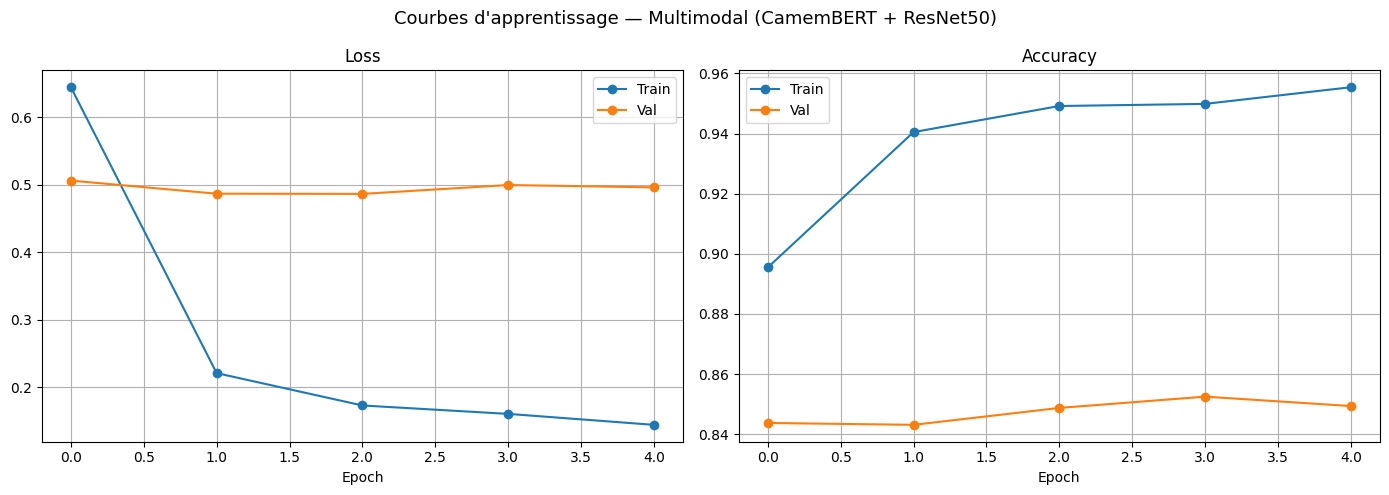

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="Train", marker="o")
axes[0].plot(val_losses,   label="Val",   marker="o")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(train_accs, label="Train", marker="o")
axes[1].plot(val_accs,   label="Val",   marker="o")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Courbes d'apprentissage — Multimodal (CamemBERT + ResNet50)", fontsize=13)
plt.tight_layout()
plt.savefig("learning_curves_multimodal.png", dpi=150)
plt.show()